[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/kernels.ipynb)

# Kernels and dynamic correlations

`tc.timecorr` estimates the correlations at each timepoint from a weighted window of nearby timepoints. The weights are the **kernel**. This notebook shows the kernels, how their shape and width change the estimates, one-sided kernels, the delta kernel, the output format, and smoothing.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr>=0.3.1" || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
plt.style.use('timecorr.tutorial')
COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']

## 1. The kernels

Each kernel function takes the number of timepoints `T` and a dict of parameters, and returns a `T x T` matrix. Row `t` holds the weights used at timepoint `t`. Each function has a default dict (`tc.gaussian_params` and so on); `plot_weights` (in `timecorr.helpers`) draws one row.

Gaussian     default parameters: {'var': 100}; shown: {'var': 25}
Laplace      default parameters: {'scale': 100}; shown: {'scale': 5}
Mexican hat  default parameters: {'sigma': 10}; shown: {'sigma': 5}
Student's t  default parameters: {'df': 100}; shown: {'df': 2}
Boxcar       default parameters: {'width': 10}; shown: {'width': 10}
Uniform      default parameters: {}; shown: {}
Delta        default parameters: {}; shown: {}


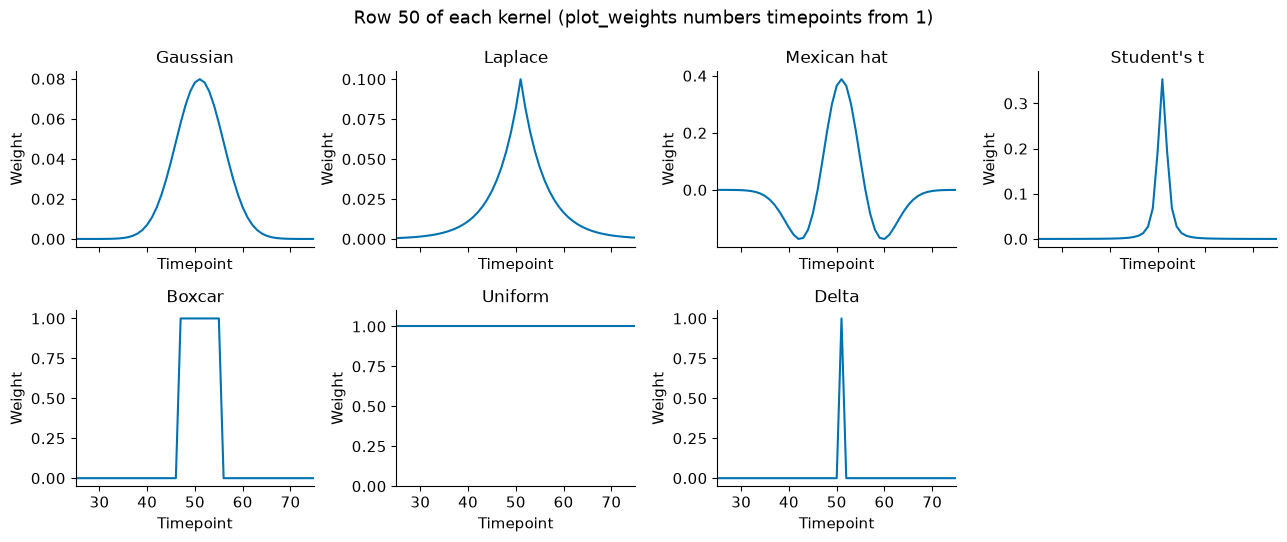

In [3]:
from timecorr.helpers import plot_weights

T, t = 100, 50
kernels = {
    'Gaussian': (tc.gaussian_weights, {'var': 25}),
    'Laplace': (tc.laplace_weights, {'scale': 5}),
    'Mexican hat': (tc.mexican_hat_weights, {'sigma': 5}),
    "Student's t": (tc.t_weights, {'df': 2}),
    'Boxcar': (tc.boxcar_weights, {'width': 10}),
    'Uniform': (tc.uniform_weights, tc.uniform_params),
    'Delta': (tc.eye_weights, tc.eye_params),
}
defaults = [tc.gaussian_params, tc.laplace_params, tc.mexican_hat_params, tc.t_params,
            tc.boxcar_params, tc.uniform_params, tc.eye_params]
for name, d in zip(kernels, defaults):
    print(f'{name:12s} default parameters: {d}; shown: {kernels[name][1]}')

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for ax, (name, (f, params)) in zip(axes.ravel(), kernels.items()):
    plot_weights(f(T, params), t=t, ax=ax, color=COLORS[0], title=name,
                 xlab="Timepoint", ylab="Weight")
    ax.set_xlim(t - 25, t + 25)
    ax.set_ylim(min(0, ax.get_ylim()[0]), None)
axes[1, 1].set_ylim(0, 1.1)
axes[1, 3].axis('off')
fig.suptitle(f'Row {t} of each kernel (plot_weights numbers timepoints from 1)')
fig.tight_layout()
plt.show()

## 2. Kernel shape

We estimate the correlations of simulated data whose true correlations change abruptly between 3 events (see the [simulation tutorial](simulate.ipynb)). The score is the correlation between the estimated and true correlations, pooled over pairs of features and timepoints.

In [4]:
T, K = 300, 10
data, truth = tc.simulate_data(datagen='block', T=T, K=K, B=3, return_corrs=True, set_random_seed=7)

def score(est, truth):
    return np.corrcoef(est[:, K:].ravel(), truth[:, K:].ravel())[0, 1]  # first K columns: diagonal

shapes = {'Gaussian (var 100)': (tc.gaussian_weights, {'var': 100}),
          'Laplace (scale 10)': (tc.laplace_weights, {'scale': 10}),
          'Boxcar (width 20)': (tc.boxcar_weights, {'width': 20}),
          'Mexican hat (sigma 5)': (tc.mexican_hat_weights, {'sigma': 5}),
          'Uniform': (tc.uniform_weights, {})}
estimates = {}
for name, (f, params) in shapes.items():
    estimates[name] = tc.timecorr(data, weights_function=f, weights_params=params)
    print(f'{name:22s} score {score(estimates[name], truth):.2f}')

Gaussian (var 100)     score 0.89
Laplace (scale 10)     score 0.89
Boxcar (width 20)      score 0.82
Mexican hat (sigma 5)  score -0.05
Uniform                score 0.56


The uniform kernel weights every timepoint equally, so it gives the static correlation at every timepoint. The Mexican hat kernel gives negative weight to timepoints a few samples away.

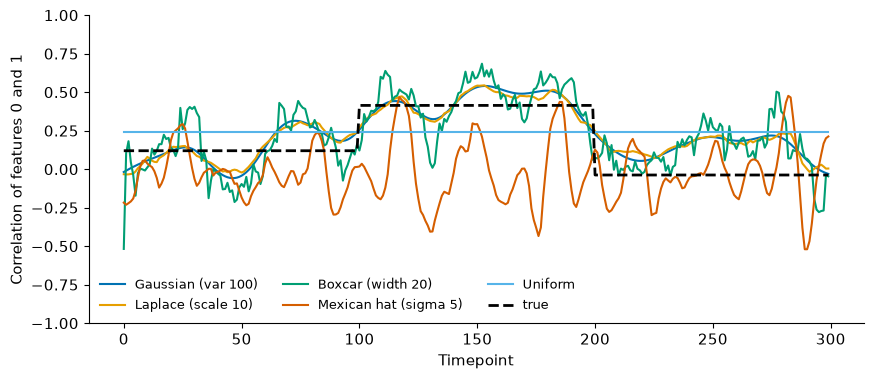

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, est in estimates.items():
    ax.plot(tc.vec2mat(est)[0, 1], lw=1.5, label=name)
ax.plot(tc.vec2mat(truth)[0, 1], color='k', ls='--', lw=2, label='true')
ax.set(xlabel='Timepoint', ylabel='Correlation of features 0 and 1', ylim=(-1, 1))
ax.legend(ncol=3, loc='lower left', fontsize=9)
plt.show()

## 3. Kernel width

A wider kernel averages over more timepoints, so its estimates are less noisy but change more slowly. The best width depends on how fast the correlations change. Below, abrupt changes (`'block'`) are compared with gradual ones (`'ramping'`).

block sd 2: 0.68 sd 4: 0.80 sd 8: 0.87 sd 16: 0.91 sd 32: 0.91 sd 64: 0.86
ramping sd 2: 0.56 sd 4: 0.70 sd 8: 0.81 sd 16: 0.89 sd 32: 0.94 sd 64: 0.95


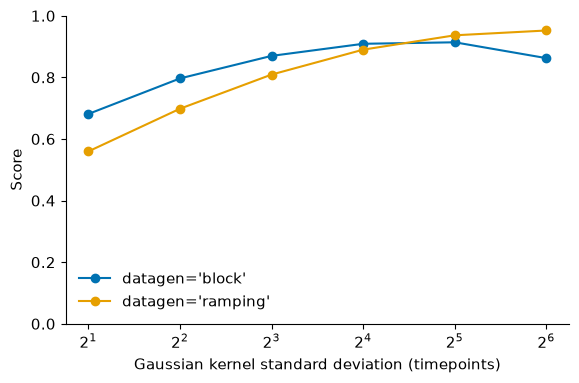

In [6]:
sds = [2, 4, 8, 16, 32, 64]
fig, ax = plt.subplots(figsize=(6.5, 4))
for kind in ['block', 'ramping']:
    d, c = tc.simulate_data(datagen=kind, T=T, K=K, B=3, return_corrs=True, set_random_seed=7)
    scores = [score(tc.timecorr(d, weights_params={'var': sd ** 2}), c) for sd in sds]
    print(kind, ' '.join(f'sd {sd}: {s:.2f}' for sd, s in zip(sds, scores)))
    ax.plot(sds, scores, 'o-', label=f"datagen='{kind}'")
ax.set_xscale('log', base=2)
ax.set(xlabel='Gaussian kernel standard deviation (timepoints)', ylabel='Score', ylim=(0, 1))
ax.legend()
plt.show()

## 4. One-sided kernels

Every kernel function takes `direction` (`'backward'`: the current and past timepoints; `'forward'`: the current and future ones) and `include_zero` (whether `t` itself counts). `tc.one_sided` does the same to any kernel matrix.

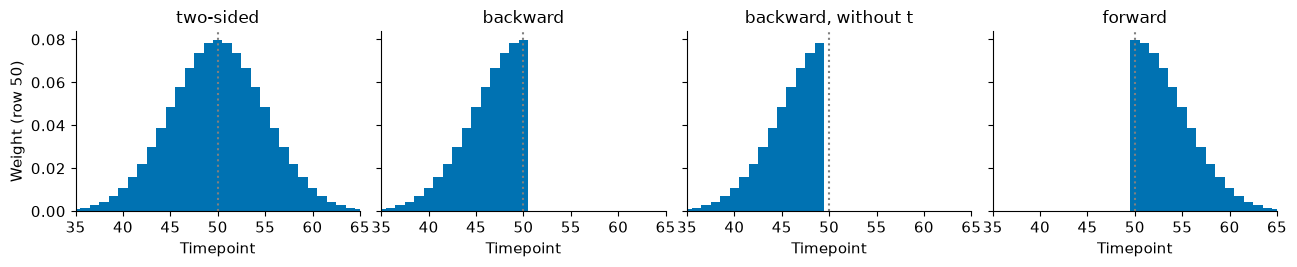

In [7]:
w = tc.gaussian_weights(100, {'var': 25})
variants = {'two-sided': w,
            'backward': tc.one_sided(w, 'backward'),
            'backward, without t': tc.one_sided(w, 'backward', include_zero=False),
            'forward': tc.gaussian_weights(100, {'var': 25}, direction='forward')}
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, (name, k) in zip(axes, variants.items()):
    ax.bar(np.arange(100), k[50], width=1, color=COLORS[0])
    ax.axvline(50, color='0.5', ls=':')
    ax.set(xlim=(35, 65), title=name, xlabel='Timepoint')
axes[0].set_ylabel('Weight (row 50)')
fig.tight_layout()
plt.show()

In `tc.timecorr`, `include_timepoints='backward'` or `'forward'` (with `include_zero`) makes the kernel one-sided, and `exclude_timepoints=x` keeps only timepoints at most `x` samples from `t` (`-x` keeps only those farther away). Rows left with fewer than 3 non-zero weights are set to 0 with a warning, printed below.

backward: 2 of 300 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
forward: 2 of 300 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.


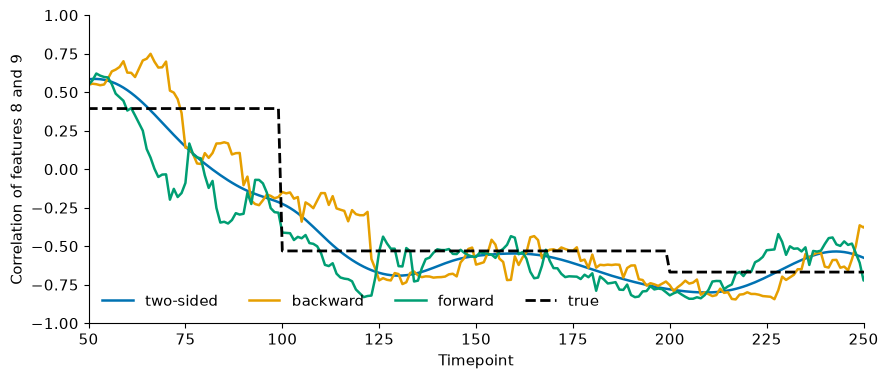

In [8]:
import warnings

settings = {'two-sided': {}, 'backward': {'include_timepoints': 'backward'},
            'forward': {'include_timepoints': 'forward'},
            'within 10 samples': {'exclude_timepoints': 10}}
one_sided = {}
for name, kw in settings.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
        one_sided[name] = tc.timecorr(data, weights_params={'var': 100}, **kw)
    caught = [w for w in caught if issubclass(w.category, UserWarning)]  # timecorr's warnings only
    for message in caught:
        print(f'{name}: {message.message}')

# the pair of features whose true correlation changes most between events
iu = np.triu_indices(K, 1)
true_mats = tc.vec2mat(truth)
pair = np.argmax(np.ptp(true_mats[iu[0], iu[1]], axis=1))
i, j = iu[0][pair], iu[1][pair]

fig, ax = plt.subplots(figsize=(10, 4))
for name in ['two-sided', 'backward', 'forward']:
    ax.plot(tc.vec2mat(one_sided[name])[i, j], lw=1.8, label=name)
ax.plot(true_mats[i, j], color='k', ls='--', lw=2, label='true')
ax.set(xlabel='Timepoint', ylabel=f'Correlation of features {i} and {j}', ylim=(-1, 1), xlim=(50, 250))
ax.legend(ncol=4, loc='lower left')
plt.show()

The backward estimate changes after each event boundary and the forward estimate before it.

## 5. The delta kernel: co-fluctuations

`tc.eye_weights` puts all weight on `t`, so `timecorr` returns each pair's **co-fluctuation**, the product of the two z-scored features at `t`. Co-fluctuations are not bounded by -1 and 1, and their mean over time is the static correlation.

largest |mean co-fluctuation - static correlation|: 8.881784197001252e-16


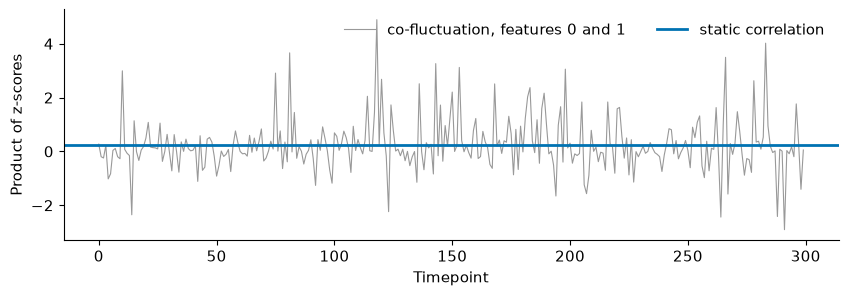

In [9]:
cofluct = tc.timecorr(data, weights_function=tc.eye_weights, weights_params=tc.eye_params)
static = np.corrcoef(data.T)
print('largest |mean co-fluctuation - static correlation|:',
      np.abs(tc.vec2mat(cofluct).mean(axis=2) - static).max())

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(tc.vec2mat(cofluct)[0, 1], color='0.6', lw=0.8, label='co-fluctuation, features 0 and 1')
ax.axhline(static[0, 1], color=COLORS[0], lw=2, label='static correlation')
ax.set(xlabel='Timepoint', ylabel='Product of z-scores')
ax.legend(loc='upper right', ncol=2)
plt.show()

## 6. The output format and the estimator

Each output row is one correlation matrix: the `K` diagonal entries, then the entries above the diagonal. `tc.vec2mat` gives a `K x K x T` array and `tc.mat2vec` goes back. `tc.wcorr` is the kernel-weighted estimator itself; it returns matrices directly.

vectorized: (300, 55) -> matrices: (10, 10, 300)
round trip exact: True
wcorr gives the same matrices: True


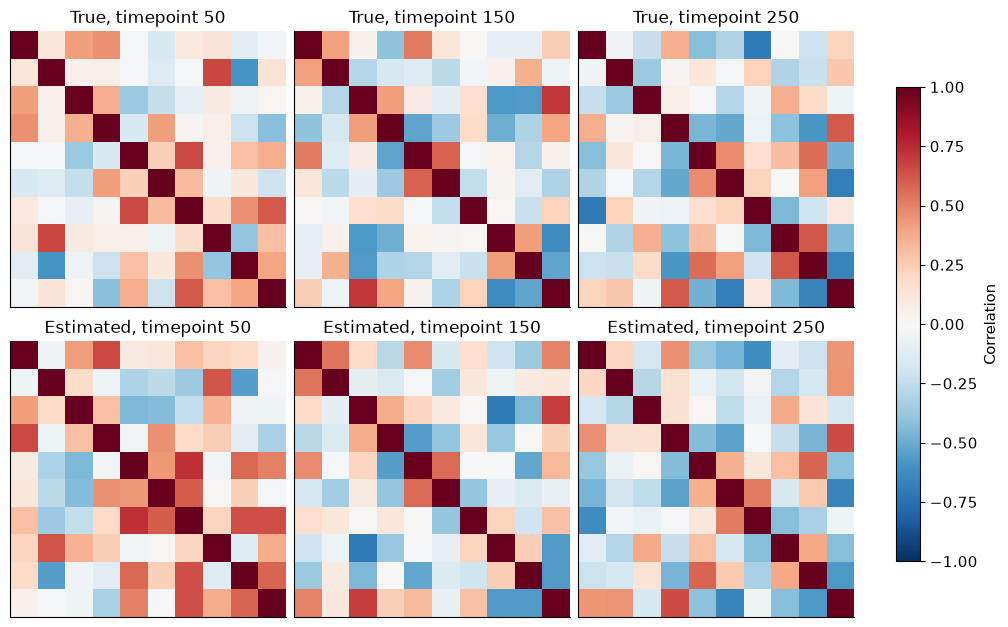

In [10]:
est = estimates['Gaussian (var 100)']
mats = tc.vec2mat(est)
print('vectorized:', est.shape, '-> matrices:', mats.shape)
print('round trip exact:', np.array_equal(tc.mat2vec(mats), est))
direct = tc.wcorr(data, data, tc.gaussian_weights(T, {'var': 100}))
print('wcorr gives the same matrices:', np.allclose(direct, mats))

true_mats = tc.vec2mat(truth)
fig, axes = plt.subplots(2, 3, figsize=(10, 6.2), layout='constrained')
for col, tp in enumerate([50, 150, 250]):
    for row, (m, label) in enumerate([(true_mats, 'True'), (mats, 'Estimated')]):
        im = axes[row, col].imshow(m[:, :, tp], cmap='RdBu_r', vmin=-1, vmax=1)
        axes[row, col].set(title=f'{label}, timepoint {tp}', xticks=[], yticks=[])
fig.colorbar(im, ax=axes, label='Correlation', shrink=0.8)
plt.show()

## 7. Smoothing

With `cfun=None`, `tc.timecorr` smooths the data with the kernel instead of correlating them. `tc.smooth` smooths with a kernel cut to a window of `windowsize` samples; for an even window it averages the two middle kernel rows (`tc.iseven` and `tc.isodd` test parity).

window 21 is odd: True | window 20 is even: True


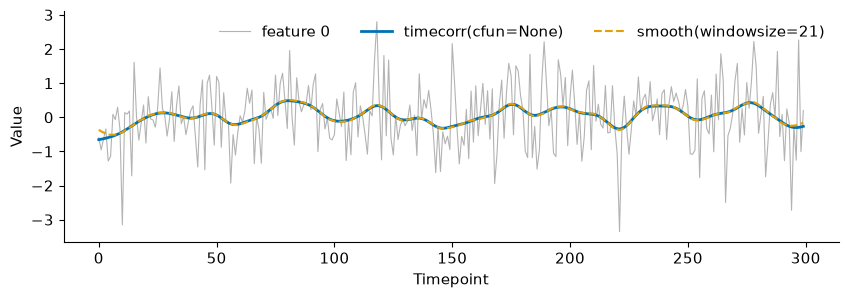

In [11]:
smoothed = tc.timecorr(data, cfun=None, weights_params={'var': 25})
windowed = tc.smooth(data, windowsize=21, weights_function=tc.gaussian_weights,
                     weights_params={'var': 25})
print('window 21 is odd:', bool(tc.isodd(21)), '| window 20 is even:', bool(tc.iseven(20)))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(data[:, 0], color='0.7', lw=0.8, label='feature 0')
ax.plot(smoothed[:, 0], lw=2, label='timecorr(cfun=None)')
ax.plot(windowed[:, 0], lw=1.5, ls='--', label='smooth(windowsize=21)')
ax.set(xlabel='Timepoint', ylabel='Value')
ax.legend(ncol=3, loc='upper right')
plt.show()

Next: [several subjects](subjects.ipynb). Kernel details and defaults are in the [API reference](https://timecorr.readthedocs.io/en/latest/api.html).

The picture on this tutorial's card in the gallery: one row of four of the kernels.

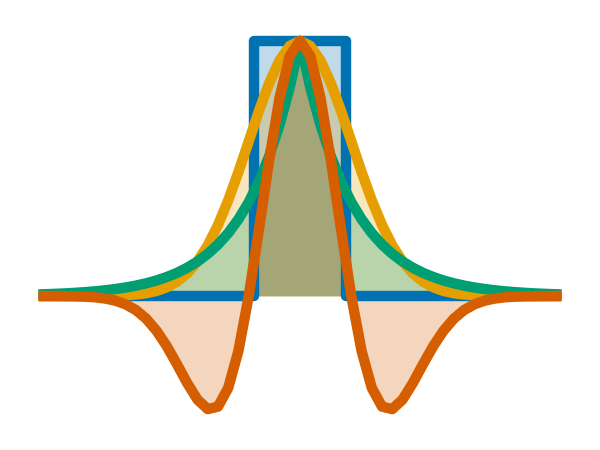

In [12]:
# the saved picture is the whole 4:3 figure (the default crops it to its content)
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}
fig = plt.figure(figsize=(4, 3), dpi=150, facecolor='white')
ax = fig.add_axes([0.03, 0.05, 0.94, 0.9])
lags = np.arange(t - 25, t + 26)
for color, name in zip(COLORS, ['Boxcar', 'Gaussian', 'Laplace', 'Mexican hat']):
    f, params = kernels[name]
    row = f(T, params)[t, lags]
    row = row / np.abs(row).max()
    ax.fill_between(lags, row, color=color, alpha=0.25, lw=0, step='mid' if name == 'Boxcar' else None)
    ax.plot(lags, row, color=color, lw=5, drawstyle='steps-mid' if name == 'Boxcar' else 'default')
ax.set_axis_off()
plt.show()